In [1]:
%pip install opencv-python-headless matplotlib scikit-learn streamlit numpy
%pip install kagglehub
# %pip install mlflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 12.1 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 18.2 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 15.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 12.0 MB/s eta 0:00:0000:010:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 15.8 MB/s eta 0:00:0000:0100:01
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.3 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 KB 24.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 33.7 MB/s eta 0:00:0000:01
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 KB 24.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 12.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.4/87.4 KB

In [2]:
import cv2
from pathlib import Path
import numpy as np
import os
import zipfile
import matplotlib.pyplot as plt 
from collections import Counter
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models,Model
from sklearn.utils import shuffle
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display
import kagglehub

2026-10-23 11:55:21.355524: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792756521.376304    1602 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792756521.382645    1602 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792756521.400845    1602 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792756521.400868    1602 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792756521.400870    1602 computation_placer.cc:177] computation placer alr

In [3]:
kagglehub.login() 


In [4]:

kagglehub.login()


path = kagglehub.dataset_download("anasdjamaoui/data-mri")

print("Path to dataset files:", path)

100%|██████████| 149M/149M [00:12<00:00, 12.9MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/anasdjamaoui/data-mri/versions/1


In [6]:
import os
import cv2

DATA_DIR = os.path.join(path, 'Data')

def load_images_from_folder_resize(folder):
    images = []
    labels = []
    valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

    for class_name in os.listdir(folder):
        class_path = os.path.join(folder, class_name)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            if not filename.lower().endswith(valid_extensions):
                continue

            image_path = os.path.join(class_path, filename)

            img = cv2.imread(image_path, cv2.IMREAD_COLOR)

            if img is not None:
                img = cv2.resize(img, (224, 224))
                images.append(img)
                labels.append(class_name)

        print(f"{class_name}: {len(images)} images loaded so far")

    return labels, images

labels, images = load_images_from_folder_resize(DATA_DIR)

print("Total loaded:", len(images))
print("Labels found:", set(labels))

glioma: 1621 images loaded so far
meningioma: 3266 images loaded so far
notumor: 5266 images loaded so far
pituitary: 7023 images loaded so far
Total loaded: 7023
Labels found: {'notumor', 'meningioma', 'glioma', 'pituitary'}


In [8]:
# DATA_DIR = os.path.join(path, 'Data')

# def load_images_from_folder_resize(folder):
#     images = []
#     labels = []
#     valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

#     for class_name in os.listdir(folder):
#         class_path = os.path.join(folder,class_name)

#         for filename in os.listdir(class_path):
#             if not filename.lower().endswith(valid_extensions):
#                 continue

#             image_path = os.path.join(class_path,filename)
#             # try :
#             img = cv2.imread(image_path,cv2.IMREAD_COLOR)
#             if img is not None:
#                 img = cv2.resize(img, (224, 224))
#                 images.append(img)
#                 labels.append(class_name)
#             # except Exception as e :
#                 # print('loading error : ', e)
#         print(f'class {class_name} loaded : {len(images)} files')
#     return labels , images



# labels , images = load_images_from_folder_resize(DATA_DIR)

In [9]:
print( len(images))
print(len(labels))
print(labels[4000:4005])

7023
7023
['notumor', 'notumor', 'notumor', 'notumor', 'notumor']


In [10]:
x = np.array(images)
y = np.array(labels)

print(x.shape)
print(y.shape)
print(x.dtype)
print(y.dtype)

(7023, 224, 224, 3)
(7023,)
uint8
<U10


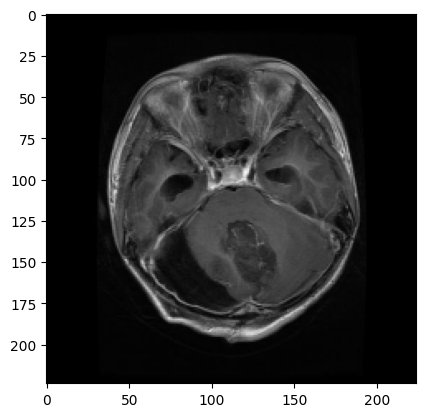

In [11]:
i = x[0]
plt.imshow(i)
plt.show()

Counter({np.str_('notumor'): 2000, np.str_('pituitary'): 1757, np.str_('meningioma'): 1645, np.str_('glioma'): 1621})


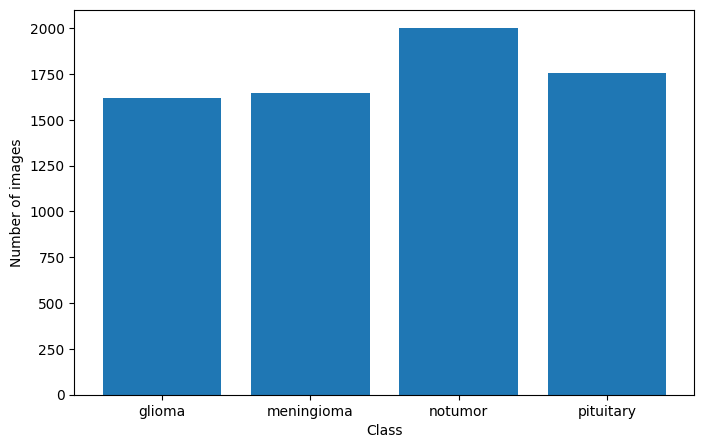

In [12]:
#repartition des images
class_counts = Counter(y)
print(class_counts)
plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())


plt.xlabel("Class")
plt.ylabel("Number of images")
plt.show()

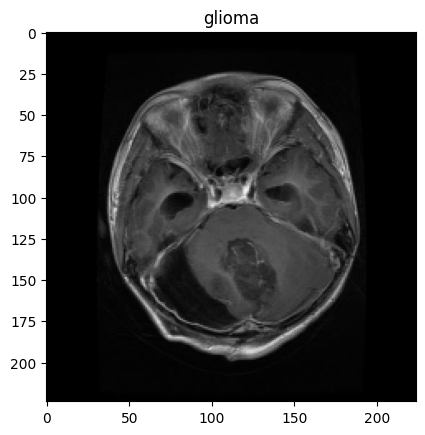

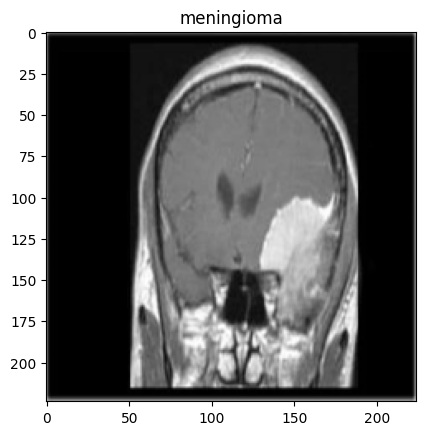

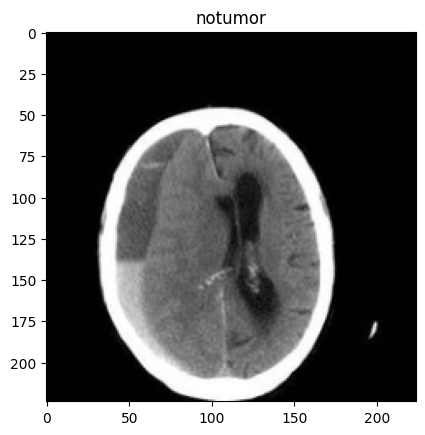

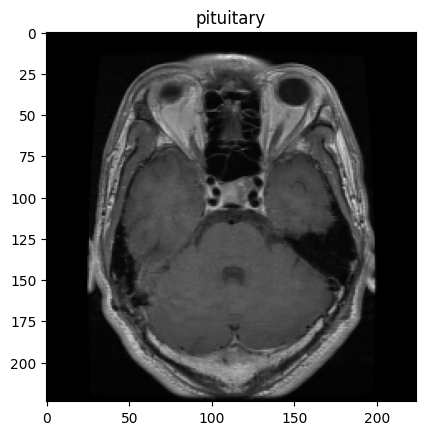

In [13]:
for key , value in class_counts.items():

    indices = np.where(y == key)[0]
    plt.imshow(x[indices[0]])
    plt.title(key)
    plt.show()
    